# X-Wines: Wine Rating Analysis
**Question:** Can historical user ratings predict a wine rating, and does wine metadata improve prediction beyond user/wine identities?

The analysis uses the official **Slim edition: 150,000 ratings**. It examines rating patterns, user activity, wine characteristics, and their predictive value under chronological, random, and unseen-wine evaluation.

`Test` names an upstream dataset edition; it is separate from the held-out test partitions used for model evaluation.

## Dataset structure

- `UserID`, `WineID`, and `RatingID` identify users, wines, and rating events.
- `Type`, multi-valued `Grapes`, and `Elaborate` describe wine categories.
- `Country` and `RegionID` describe production origin. Consumer locations and geographic coordinates are unavailable.
- `Date` records the rating time; `Vintage` records the harvest year.
- Prices, sales, and purchase exposures are unavailable. The analysis uses observed ratings and available wine attributes.

In [1]:
from pathlib import Path
import sys, json, os
ROOT = Path.cwd()
if not (ROOT/'src/experiments.py').exists(): ROOT = ROOT.parent
assert (ROOT/'src/experiments.py').exists(), 'Run from repo root or notebooks/'
sys.path.insert(0,str(ROOT))
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'.cache/matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import spearmanr
from src.experiments import (SEED, SPECS, load_data, audit, make_splits,
    coverage_table, group_summary, paired_type_effect, export_splits,
    run_protocol, sha256, time_diagnostic)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False,
                     'axes.spines.right':False, 'font.size':10})
REPORTS = ROOT/'reports'; REPORTS.mkdir(exist_ok=True)
FIGURES = REPORTS/'figures'; FIGURES.mkdir(exist_ok=True)
VERSION = 'Slim'  # explicit; never silently fall back to the tiny Test edition
print('Seed:',SEED,'Edition:',VERSION)
print('Python:',sys.version.split()[0])

Seed: 258 Edition: Slim
Python: 3.11.13


## Data provenance and quality

Run `python scripts/download_data.py` first. Inputs are pinned by SHA-256; GitHub example CSVs also pin the source commit. Slim is obtained from the official Google Drive linked by the authors. Raw data and regenerated splits stay out of Git; the notebook embeds executed outputs.

The authors report Full: 100,646 wines, 1,056,079 users, 21,013,536 ratings. These are **published counts, not measurements from this run**. Verify the actual editions below. List fields are parsed with `ast.literal_eval`; IDs remain categorical. Repeated user/wine events can be valid different vintages in Full, so we do not blindly delete them.

In [2]:
sources = json.loads((ROOT/'data/sources.json').read_text())
for name, info in sources['files'].items():
    assert sha256(ROOT/'data/raw'/name) == info['sha256'], f'Changed input: {name}'
wines, ratings = load_data(ROOT/'data/raw', VERSION)
example_wines, example_ratings = load_data(ROOT/'data/raw', 'Test')
summary = pd.concat([audit(example_wines,example_ratings).rename('Test edition'),
                     audit(wines,ratings).rename('Slim edition')],axis=1)
display(summary)
summary.to_csv(REPORTS/'dataset_summary.csv')
display(wines.drop(columns=['GrapeList','HarmonizeList']).head(3))
display(ratings.head(3))

,Test edition,Slim edition
ratings,1000,150000
users,636,10561
catalog_wines,100,1007
rated_wines,100,1007
countries,17,31
regions,77,324
wine_types,6,6
date_min,2012-07-19 12:40:37,2012-04-19 20:46:00
date_max,2021-12-31 12:17:41,2021-12-31 23:58:52
sparsity,0.984277,0.985896


,WineID,WineName,Type,Elaborate,Grapes,Harmonize,ABV,Body,Acidity,Code,Country,RegionID,RegionName,WineryID,WineryName,Website,Vintages
0,100001,Espumante Moscatel,Sparkling,Varietal/100%,['Muscat/Moscato'],"['Pork', 'Rich Fish', 'Shellfish']",7.5,Medium-bodied,High,BR,Brazil,1001,Serra Gaúcha,10001,Casa Perini,http://www.vinicolaperini.com.br,"[2020, 2019, 2018, 2017, 2016, 2015, 2014, 201..."
1,100002,Ancellotta,Red,Varietal/100%,['Ancellotta'],"['Beef', 'Barbecue', 'Codfish', 'Pasta', 'Pizz...",12.0,Medium-bodied,Medium,BR,Brazil,1001,Serra Gaúcha,10001,Casa Perini,http://www.vinicolaperini.com.br,"[2016, 2015, 2014, 2013, 2012, 2011, 2010, 200..."
2,100003,Cabernet Sauvignon,Red,Varietal/100%,['Cabernet Sauvignon'],"['Beef', 'Lamb', 'Poultry']",12.0,Full-bodied,High,BR,Brazil,1001,Serra Gaúcha,10002,Castellamare,https://www.emporiocastellamare.com.br,"[2021, 2020, 2019, 2018, 2017, 2016, 2015, 201..."


,RatingID,UserID,WineID,Vintage,Rating,Date
0,143,1356810,103471,1950,4.5,2021-11-02 20:52:59
1,199,1173759,111415,1951,5.0,2015-08-20 17:46:26
2,348,1164877,111395,1952,5.0,2020-11-13 05:40:26


In [3]:
quality = pd.DataFrame({'missing':wines.isna().sum(),
    'unique_values':wines.drop(columns=['GrapeList','HarmonizeList']).nunique()})
display(quality.dropna())
quality.to_csv(REPORTS/'metadata_quality.csv')
print('Observed scale:',sorted(ratings.Rating.unique()))
print('Metadata columns:',', '.join(wines.columns[:17]))
print('Review-derived Body/Acidity excluded from default probes; price absent.')

,missing,unique_values
ABV,0,76.0
Acidity,0,3.0
Body,0,5.0
Code,0,31.0
Country,0,31.0
Elaborate,0,13.0
Grapes,0,304.0
Harmonize,0,205.0
RegionID,0,324.0
RegionName,0,324.0


Observed scale: [np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]
Metadata columns: WineID, WineName, Type, Elaborate, Grapes, Harmonize, ABV, Body, Acidity, Code, Country, RegionID, RegionName, WineryID, WineryName, Website, Vintages
Review-derived Body/Acidity excluded from default probes; price absent.


## Prediction target and evaluation splits

Primary estimand: **a later rating event in the sampled catalogue**, given user identity, wine identity and metadata assumed available at prediction time. We predict the continuous conditional mean, clip to [1,5], and do not round to half-stars. RMSE is primary; MAE is secondary. Unobserved pairs are not zero-star ratings.

- **Primary:** global chronological 80/10/10 by events, with all timestamp ties kept together. Training precedes validation, which precedes test. Fractions may differ slightly at ties.
- **Sensitivity:** seeded random user–wine-pair groups, preventing repeat-pair leakage if later adapted to Full. Random splitting answers a different question; its scores are not directly a measure of temporal leakage.
- **Stress test:** seeded disjoint wine groups; all interactions for a wine stay in one partition. This simulates unavailable item histories, not actual wine launch dates. Users may occur across partitions.

Unknown user/item one-hot keys contribute zero (global/content fallback); mean baselines back off to the training global mean. Coverage is reported; no cold rows are silently dropped. Validation tunes models; the held-out test is used only for prespecified references plus the selected metadata representation. Models remain fitted on train for comparable history slices.

In [4]:
protocols = ['chronological','random','cold_item']
splits = {p:make_splits(ratings,p) for p in protocols}
manifests = {p:export_splits(splits[p],p,ROOT/'data/processed'/VERSION) for p in protocols}
(REPORTS/'split_manifests.json').write_text(json.dumps(manifests,indent=2)+'\n')
coverage = pd.concat([coverage_table(s).assign(protocol=p) for p,s in splits.items()],ignore_index=True)
display(coverage)
coverage.to_csv(REPORTS/'split_coverage.csv',index=False)
train = splits['chronological']['train']
train_joined = train.merge(wines,on='WineID',validate='many_to_one')
print('Feature/hypothesis exploration below uses chronological TRAIN only.')

,partition,n,users,wines,start,end,warm_both,new_user_only,new_item_only,new_both,mean_rating,protocol
0,train,120000,10357,1000,2012-04-19 20:46:00,2020-08-25 01:57:25,1.000000,0.000000,0.000000,0.000000,3.784362,chronological
1,validation,15000,6081,838,2020-08-25 02:29:49,2021-04-20 23:20:48,0.946467,0.053133,0.000267,0.000133,3.934300,chronological
2,test,15000,5788,822,2021-04-20 23:30:05,2021-12-31 23:58:52,0.933533,0.065400,0.000933,0.000133,3.991100,chronological
3,train,120000,10512,1005,2012-04-19 20:46:00,2021-12-31 23:58:52,1.000000,0.000000,0.000000,0.000000,3.818996,random
4,validation,15000,7665,863,2012-05-15 00:01:18,2021-12-31 22:50:09,0.998600,0.001333,0.000067,0.000000,3.824533,random
5,test,15000,7700,859,2012-04-21 19:04:41,2021-12-31 23:20:17,0.997933,0.002000,0.000067,0.000000,3.823800,random
6,train,126964,10493,805,2012-04-19 20:46:00,2021-12-31 23:58:52,1.000000,0.000000,0.000000,0.000000,3.829798,cold_item
7,validation,8500,5439,101,2012-05-24 12:38:18,2021-12-31 23:33:56,0.000000,0.000000,0.995647,0.004353,3.777824,cold_item
8,test,14536,7628,101,2012-05-15 00:54:22,2021-12-31 23:49:55,0.000000,0.000000,0.997867,0.002133,3.759390,cold_item


Feature/hypothesis exploration below uses chronological TRAIN only.


## Ratings, sparsity and activity

Whole-edition plots describe the sample; they do not select models. Train-only plots below motivate feature probes. Catalogue-level counts and review-level counts answer different questions. The observed rating distribution is conditioned on users choosing to rate; it is not the distribution of all tastes or purchases.

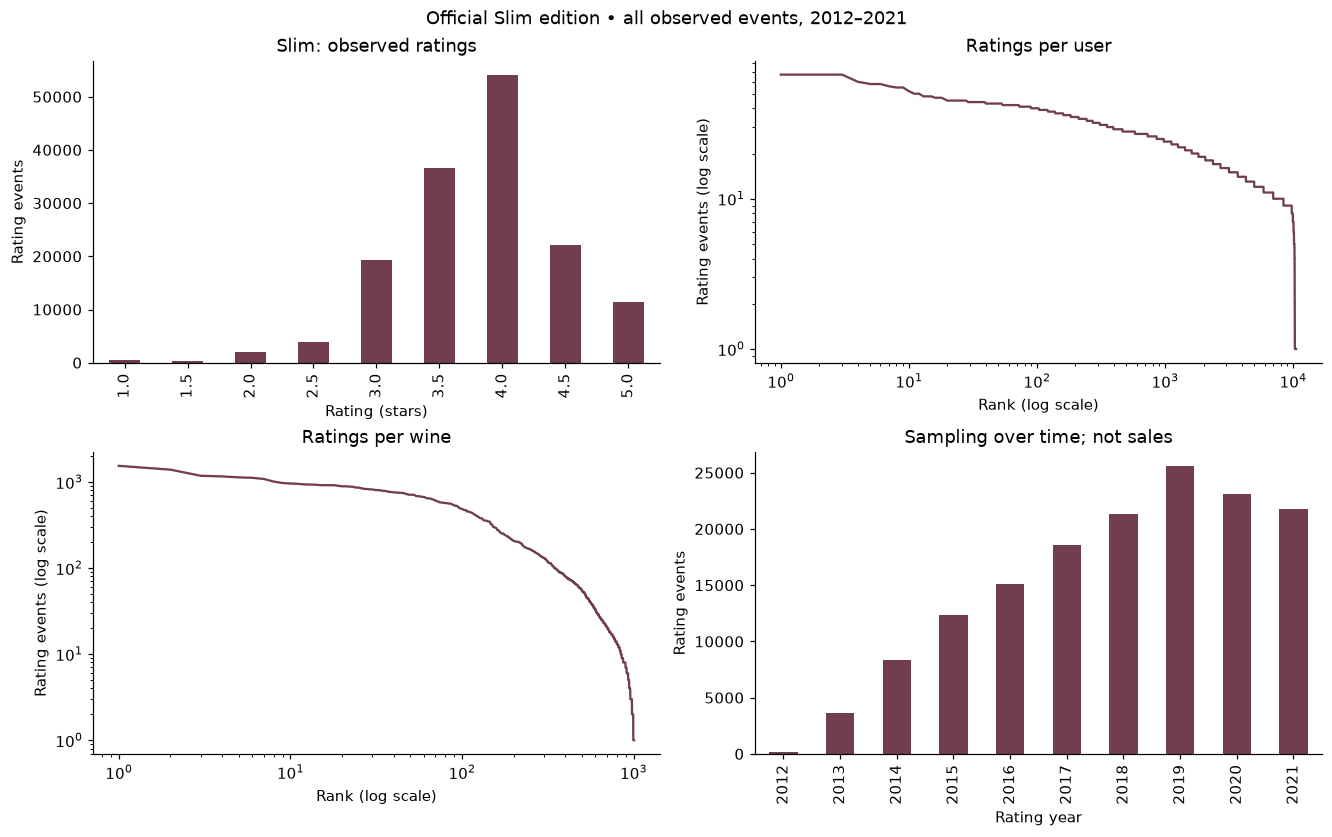

,UserID,WineID
count,10561.000000,1007.000000
mean,14.203200,148.957299
std,7.043546,227.946427
min,1.000000,1.000000
50%,12.000000,53.000000
90%,24.000000,480.400000
95%,28.000000,711.000000
99%,39.000000,951.160000
max,67.000000,1540.000000


In [5]:
fig, ax = plt.subplots(2,2,figsize=(12,7.5),layout='constrained')
ratings.Rating.value_counts().sort_index().plot.bar(ax=ax[0,0],color='#713e50')
ax[0,0].set(xlabel='Rating (stars)',ylabel='Rating events',title=f'{VERSION}: observed ratings')
for key, axis, title in [('UserID',ax[0,1],'Ratings per user'),('WineID',ax[1,0],'Ratings per wine')]:
    counts = ratings[key].value_counts().sort_values(ascending=False).to_numpy()
    axis.loglog(np.arange(1,len(counts)+1),counts,color='#713e50')
    axis.set(xlabel='Rank (log scale)',ylabel='Rating events (log scale)',title=title)
ratings.groupby(ratings.Date.dt.year).size().plot.bar(ax=ax[1,1],color='#713e50')
ax[1,1].set(xlabel='Rating year',ylabel='Rating events',title='Sampling over time; not sales')
fig.suptitle('Official Slim edition • all observed events, 2012–2021')
fig.savefig(FIGURES/'rating_activity.png',bbox_inches='tight'); plt.show()
tails = pd.DataFrame({k:ratings[k].value_counts().describe(percentiles=[.5,.9,.95,.99])
                      for k in ['UserID','WineID']})
display(tails)
tails.to_csv(REPORTS/'activity_quantiles.csv')

## Origin, type and grape distributions

Report category support alongside averages. Equal-wine means reduce weighting by wine popularity but do not remove user selection or confounding. Grape review counts below are fractional: a blend with k listed grapes contributes 1/k to each, so total weighted counts equal rating events. Geographic labels mean production origin, not consumer location.

,ratings,users,wines,mean_rating,equal_wine_mean
Type,,,,,
Red,79726,10171,506,3.828444,3.683592
White,19186,7348,230,3.641822,3.566809
Sparkling,13472,5938,98,3.789230,3.695046
Rosé,3711,2796,83,3.399623,3.368821
Dessert/Port,2000,1570,25,3.818750,3.869493
Dessert,1905,1623,58,4.054068,3.854475


,ratings,users,wines,mean_rating,equal_wine_mean
Country,,,,,
France,31617,7959,179,3.943306,3.781688
Argentina,16421,6197,50,3.653158,3.550517
United States,14292,5715,113,3.947488,3.879850
Portugal,10445,4927,83,3.631833,3.621205
Chile,9286,4669,69,3.625512,3.367845
Italy,9240,5120,137,3.785606,3.667375
Spain,6393,4132,48,3.798217,3.534611
Brazil,6164,2383,48,3.531392,3.374578
New Zealand,4487,2901,33,3.701137,3.723496


,weighted_events,weighted_rating_sum,raw_events,mean_rating
GrapeList,,,,
Cabernet Sauvignon,18192.000000,72355.122222,27223,3.977304
Malbec,13291.230952,48215.007937,15203,3.627580
Chardonnay,11117.642857,42826.644048,14223,3.852133
Pinot Noir,8251.214286,31265.044048,11102,3.789145
Sauvignon Blanc,6677.750000,24750.016667,7440,3.706341
Merlot,5561.180952,21898.952381,12493,3.937824
Cabernet Franc,5103.533333,21334.608333,9488,4.180360
Syrah/Shiraz,4192.514286,16232.457937,8564,3.871772
Riesling,3695.733333,13531.850000,4006,3.661479


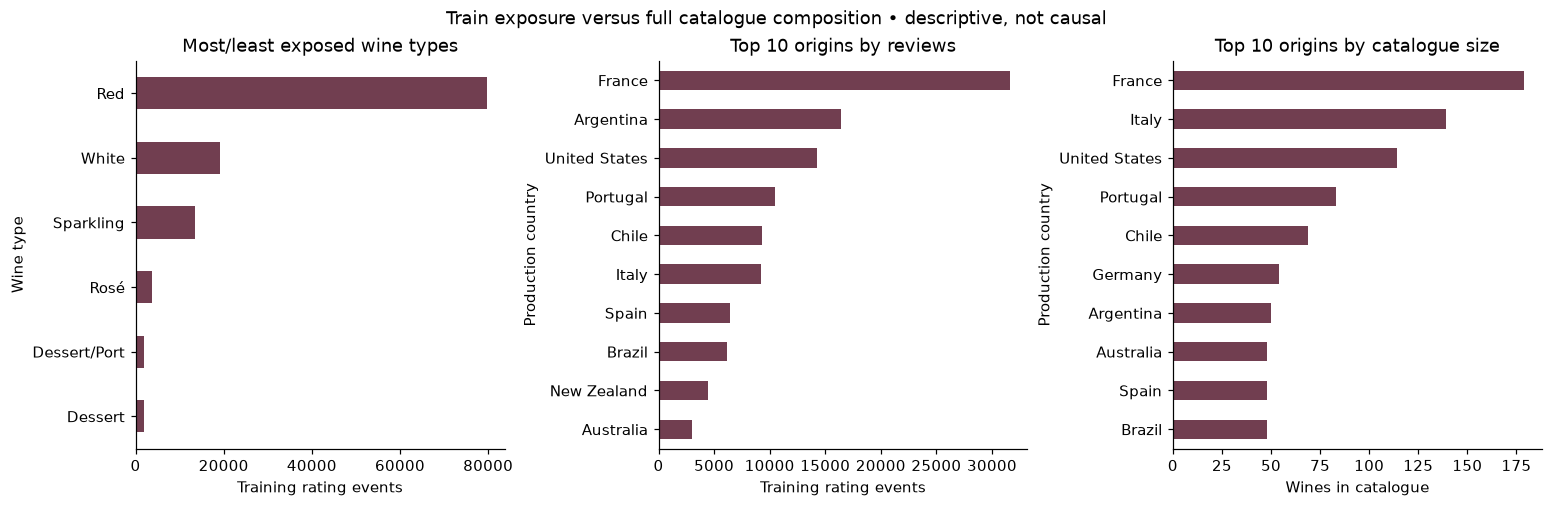

In [6]:
type_stats = group_summary(train_joined,'Type')
country_stats = group_summary(train_joined,'Country')
region_stats = group_summary(train_joined,'RegionName')
display(type_stats); display(country_stats.head(12))
for name, frame in [('type',type_stats),('country',country_stats),('region',region_stats)]:
    frame.to_csv(REPORTS/f'train_{name}_summary.csv')
grapes = train_joined[['RatingID','Rating','GrapeList']].copy()
grapes['weight'] = 1/grapes.GrapeList.map(len).clip(lower=1)
grapes = grapes.explode('GrapeList').dropna(subset=['GrapeList'])
grapes['weighted_rating'] = grapes.Rating*grapes.weight
grape_stats = grapes.groupby('GrapeList').agg(weighted_events=('weight','sum'),
    weighted_rating_sum=('weighted_rating','sum'),raw_events=('RatingID','size'))
grape_stats['mean_rating'] = grape_stats.weighted_rating_sum/grape_stats.weighted_events
grape_stats = grape_stats.sort_values('weighted_events',ascending=False)
display(grape_stats.head(12)); grape_stats.to_csv(REPORTS/'train_grape_summary.csv')
fig,ax = plt.subplots(1,3,figsize=(14,4.5),layout='constrained')
type_stats.ratings.sort_values().plot.barh(ax=ax[0],color='#713e50')
ax[0].set(xlabel='Training rating events',ylabel='Wine type',title='Most/least exposed wine types')
country_stats.ratings.head(10).sort_values().plot.barh(ax=ax[1],color='#713e50')
ax[1].set(xlabel='Training rating events',ylabel='Production country',title='Top 10 origins by reviews')
wines.Country.value_counts().head(10).sort_values().plot.barh(ax=ax[2],color='#713e50')
ax[2].set(xlabel='Wines in catalogue',ylabel='Production country',title='Top 10 origins by catalogue size')
fig.suptitle('Train exposure versus full catalogue composition • descriptive, not causal')
fig.savefig(FIGURES/'categories_origins.png',bbox_inches='tight'); plt.show()

## User effects and wine popularity

**H1:** Users who rated both Red and White rate the two types differently. Compare each user's Red mean minus White mean, requiring at least two ratings per type. Bootstrap users, weight each eligible user equally, and interpret only within that selected group.

**H2:** Popular wines have higher observed mean ratings. Spearman association uses training wine counts and means. This association is descriptive; reverse causality, user composition and noisy rare-wine means prevent a popularity-causation claim. Neither analysis justifies a causal statement about a country's or grape's intrinsic quality.

eligible_users    4630.000000
mean_delta           0.160191
ci_low               0.148260
ci_high              0.172679
Name: Red minus White (stars), dtype: float64

Train wine popularity–mean-rating Spearman rho=0.120; nominal p=0.000148
Nominal p assumes independent wines; treat as descriptive given shared users.


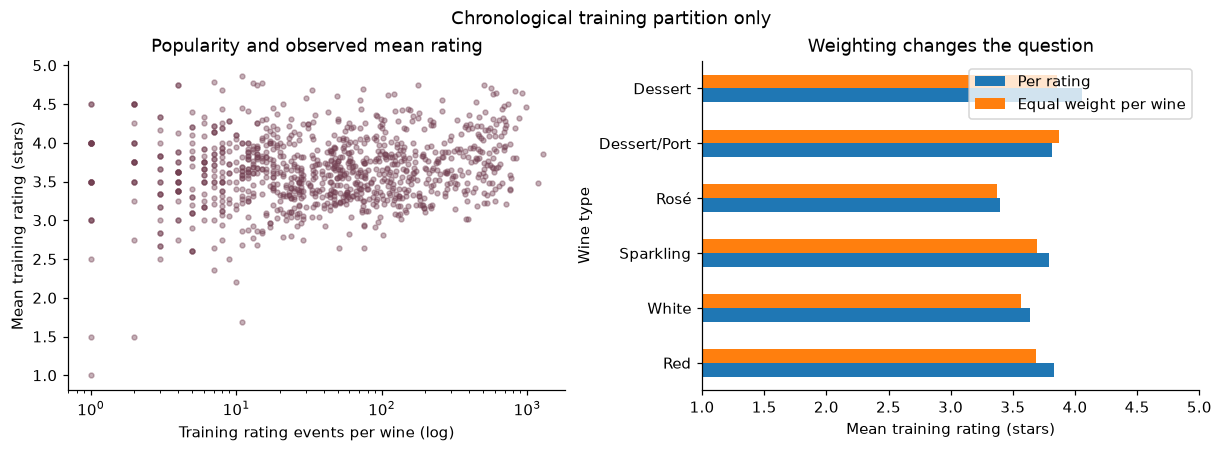

In [7]:
effect = paired_type_effect(train_joined)
display(pd.Series(effect,name='Red minus White (stars)'))
wine_stats = train.groupby('WineID').Rating.agg(['size','mean'])
rho,pvalue = spearmanr(wine_stats['size'],wine_stats['mean'])
print(f'Train wine popularity–mean-rating Spearman rho={rho:.3f}; nominal p={pvalue:.3g}')
print('Nominal p assumes independent wines; treat as descriptive given shared users.')
(REPORTS/'eda_effects.json').write_text(json.dumps({'red_white':effect,
    'popularity_spearman':float(rho),'popularity_nominal_p':float(pvalue)},indent=2)+'\n')
fig,ax = plt.subplots(1,2,figsize=(11,4),layout='constrained')
ax[0].scatter(wine_stats['size'],wine_stats['mean'],s=10,alpha=.4,color='#713e50')
ax[0].set(xscale='log',xlabel='Training rating events per wine (log)',
          ylabel='Mean training rating (stars)',title='Popularity and observed mean rating')
type_stats[['mean_rating','equal_wine_mean']].plot.barh(ax=ax[1],xlim=(1,5))
ax[1].set(xlabel='Mean training rating (stars)',ylabel='Wine type',title='Weighting changes the question')
ax[1].legend(['Per rating','Equal weight per wine'])
fig.suptitle('Chronological training partition only')
fig.savefig(FIGURES/'associations.png',bbox_inches='tight'); plt.show()

## Temporal patterns and taste concentration

Year/month counts describe the collected review process, not consumption demand. Type concentration is the share of a user's training reviews in their most frequent type. Compare against 100 permutations of type labels across events, preserving user activity and global type frequencies. This is an exploratory reference distribution, not a test of the causal origin of tastes.

,size,mean
Date,,
2012,191,4.007853
2013,3640,3.624038
2014,8350,3.674072
2015,12322,3.704431
2016,15145,3.714130
2017,18614,3.763861
2018,21330,3.814487
2019,25551,3.853900
2020,14857,3.883489


Users with >=5 train ratings: 9,411
Mean dominant-type share: observed 0.689; shuffled 0.668


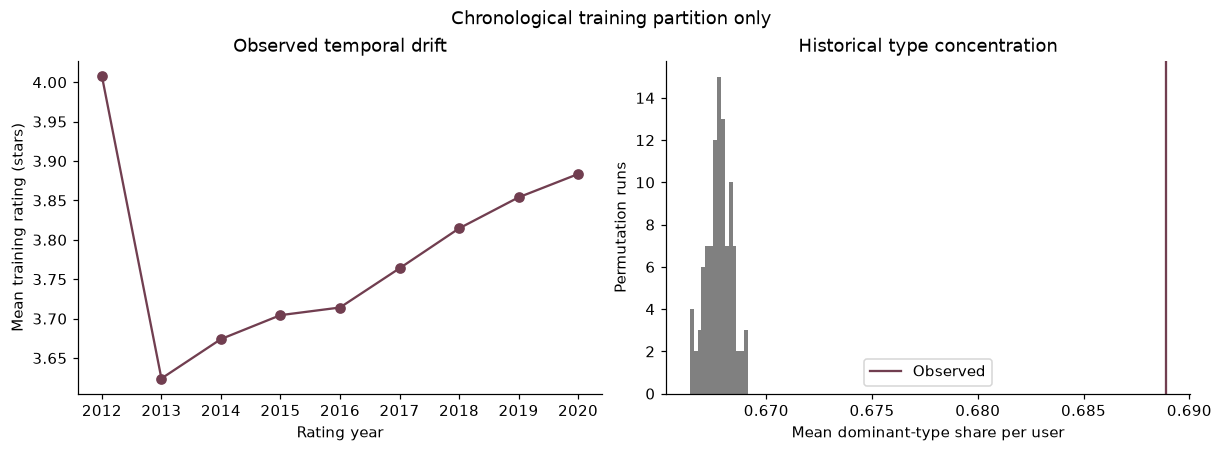

In [8]:
year_stats = train.groupby(train.Date.dt.year).Rating.agg(['size','mean'])
display(year_stats); year_stats.to_csv(REPORTS/'train_year_summary.csv')
eligible_users = train.UserID.value_counts().loc[lambda x:x>=5].index
taste = train_joined[train_joined.UserID.isin(eligible_users)][['UserID','Type']].copy()
def concentration(frame):
    counts = frame.groupby(['UserID','Type']).size()
    return (counts.groupby(level=0).max()/counts.groupby(level=0).sum()).mean()
observed = concentration(taste)
rng = np.random.default_rng(SEED)
null = []
for _ in range(100):
    perm = taste.copy(); perm['Type'] = rng.permutation(perm.Type.to_numpy())
    null.append(concentration(perm))
print(f'Users with >=5 train ratings: {len(eligible_users):,}')
print(f'Mean dominant-type share: observed {observed:.3f}; shuffled {np.mean(null):.3f}')
(REPORTS/'taste_concentration.json').write_text(json.dumps({'eligible_users':len(eligible_users),
    'observed':observed,'permutation_mean':float(np.mean(null)),
    'permutation_2_5':float(np.quantile(null,.025)),
    'permutation_97_5':float(np.quantile(null,.975))},indent=2)+'\n')
fig,ax = plt.subplots(1,2,figsize=(11,4),layout='constrained')
year_stats['mean'].plot(ax=ax[0],marker='o',color='#713e50')
ax[0].set(xlabel='Rating year',ylabel='Mean training rating (stars)',title='Observed temporal drift')
ax[1].hist(null,bins=15,color='gray'); ax[1].axvline(observed,color='#713e50',label='Observed')
ax[1].set(xlabel='Mean dominant-type share per user',ylabel='Permutation runs',title='Historical type concentration')
ax[1].legend(); fig.suptitle('Chronological training partition only')
fig.savefig(FIGURES/'time_taste.png',bbox_inches='tight'); plt.show()

## Features and preprocessing

- **IDs:** categorical `UserID`, `WineID`. Ridge on one-hot IDs is a regularized additive user/item bias reference, not matrix factorization.
- **Origin/content:** one-hot type, country, region, winery and elaborate; grape lists use fractional multi-hot values. ABV is centered/scaled using unique training wines, median-imputed if needed, with a missing indicator. Fit all vocabularies on train; unknown values contribute zero.
- **Time/context:** optional month sin/cos, scaled rating year, age = rating year minus rated Vintage; invalid/future ages become missing. `N.V.` stays missing, not year zero. These require the rating date and vintage to be known for the query.
- **Preferences:** user×type interactions test whether conditional preferences add signal. Users and categories with no train support back off to other terms.
- **Excluded:** price (absent), user location (absent), label/name/website (identifiers or difficult to justify), entire wine `Vintages` list (includes future availability), Body/Acidity in primary probes (partly derived from user comments), Harmonize (provenance uncertain).
- **Aggregates:** historical means/counts must use training data at the evaluation cutoff. For training rows used by a downstream regressor, target aggregates require out-of-fold or strictly prior computation; never use that row's rating in its own feature. No target-aggregate features are passed to these ridge probes.

**Availability limitation:** the catalogue was assembled in 2022, after the 2012–2021 ratings. This is a retrospective experiment assuming stable item metadata; an event-time split cannot prove historical availability. ABV/grapes can vary by vintage. Cold-item results assume metadata for an unseen wine is known.

## Feature comparison experiments

The same sparse ridge objective, three regularization values (1, 10, 100), fixed partitions, clipping and metrics apply to all representations. Train/validation RMSE and runtime are saved. Probe comparisons isolate *predictive utility conditional on this model*, not causal feature importance. Metadata can be redundant with WineID for warm items; lack of improvement does not prove metadata is useless for MF or cold items.

Primary comparison: validation-selected metadata probe versus validation-tuned IDs reference, evaluated on the chronological test. Random and cold-item protocols are sensitivity analyses. Test labels never select alpha or representation. Exploratory validation sweeps are not significance tests; the reported paired confidence interval belongs to the selected test comparison.

In [9]:
results = {}
results['chronological'] = run_protocol(wines,splits['chronological'],'chronological',REPORTS)
display(results['chronological']['grid'].sort_values('rmse').head(12))

chronological: ids validation RMSE 0.4544


chronological: content validation RMSE 0.4860


chronological: ids_type validation RMSE 0.4555


chronological: ids_country validation RMSE 0.4553


chronological: ids_grapes validation RMSE 0.4551


chronological: ids_region validation RMSE 0.4544


chronological: ids_metadata validation RMSE 0.4539


chronological: ids_metadata_time validation RMSE 0.4440


chronological: user_taste validation RMSE 0.4530


,protocol,representation,alpha,features,seconds,train_rmse,rmse,mae
22,chronological,ids_metadata_time,10.0,12709,1.994720,0.458857,0.443972,0.321395
21,chronological,ids_metadata_time,1.0,12709,2.224518,0.436578,0.452043,0.328310
25,chronological,user_taste,10.0,42150,1.560673,0.440489,0.453024,0.335933
19,chronological,ids_metadata,10.0,12704,1.438555,0.461486,0.453905,0.337391
1,chronological,ids,10.0,11357,0.607661,0.464302,0.454369,0.336834
16,chronological,ids_region,10.0,11678,0.706339,0.462416,0.454375,0.337588
13,chronological,ids_grapes,10.0,11544,0.799290,0.463572,0.455095,0.338118
10,chronological,ids_country,10.0,11388,0.707909,0.463422,0.455296,0.338443
7,chronological,ids_type,10.0,11363,0.690859,0.463934,0.455461,0.338520
6,chronological,ids_type,1.0,11363,0.733850,0.438899,0.458694,0.337627


In [10]:
results['random'] = run_protocol(wines,splits['random'],'random',REPORTS)
display(results['random']['scores'])

random: ids validation RMSE 0.4646


random: content validation RMSE 0.5182


random: ids_type validation RMSE 0.4645


random: ids_country validation RMSE 0.4645


random: ids_grapes validation RMSE 0.4645


random: ids_region validation RMSE 0.4645


random: ids_metadata validation RMSE 0.4645


random: ids_metadata_time validation RMSE 0.4610


random: user_taste validation RMSE 0.4700


,protocol,model,representation,rmse,mae
0,random,global,global,0.646253,0.507974
1,random,user_mean,user_mean,0.609468,0.469013
2,random,item_mean,item_mean,0.514891,0.381146
3,random,ids,ids,0.470184,0.343800
4,random,selected_metadata,ids_metadata_time,0.466090,0.340434


In [11]:
# Fewer purposeful representations for the disjoint-wine stress test.
cold_specs = {k:SPECS[k] for k in ['ids','content','ids_metadata','ids_metadata_time','user_taste']}
results['cold_item'] = run_protocol(wines,splits['cold_item'],'cold_item',REPORTS,specs=cold_specs)
display(results['cold_item']['scores'])

cold_item: ids validation RMSE 0.6132


cold_item: content validation RMSE 0.5893


cold_item: ids_metadata validation RMSE 0.5582


cold_item: ids_metadata_time validation RMSE 0.5481


cold_item: user_taste validation RMSE 0.5590


,protocol,model,representation,rmse,mae
0,cold_item,global,global,0.688437,0.545141
1,cold_item,user_mean,user_mean,0.639677,0.498164
2,cold_item,item_mean,item_mean,0.688437,0.545141
3,cold_item,ids,ids,0.675886,0.530108
4,cold_item,selected_metadata,ids_metadata_time,0.574482,0.449042


## Uncertainty and error analysis

Use a **paired user-cluster bootstrap**, 2,000 resamples with replacement, resampling entire users and comparing both predictions on identical rows. Negative ΔRMSE favors the metadata probe. The interval measures test-user sampling uncertainty conditional on a fixed split, fitted models and selected hyperparameters; it does not capture retraining or temporal distribution uncertainty. Users can share wines, so item dependence remains a limitation.

Check warm/new-user/new-item/new-both regimes and training activity/popularity bands. Micro-RMSE weights events; macro-user RMSE weights users equally. Small slices must show support. Report failure as a finding rather than tune on test. If models are changed after viewing this test, use a fresh final holdout or explicitly label further results exploratory.

In [12]:
scores = pd.concat([r['scores'] for r in results.values()],ignore_index=True)
intervals = pd.DataFrame([r['bootstrap'] for r in results.values()])
display(scores.round(4)); display(intervals.round(4))
scores.to_csv(REPORTS/'all_test_metrics.csv',index=False)
intervals.to_csv(REPORTS/'all_uncertainty.csv',index=False)
slices = pd.concat([r['slices'].assign(protocol=p) for p,r in results.items()],ignore_index=True)
display(slices.query("protocol == 'chronological' and model in ['ids','selected_metadata']"))
macro = []
for p in protocols:
    predictions = pd.read_csv(REPORTS/f'{p}_test_predictions.csv')
    for name in ['global','user_mean','item_mean','ids','selected_metadata']:
        mse = (predictions.Rating-predictions[name])**2
        macro.append(dict(protocol=p,model=name,
            macro_user_rmse=float(np.sqrt(mse.groupby(predictions.UserID).mean()).mean())))
macro = pd.DataFrame(macro); display(macro.round(4))
macro.to_csv(REPORTS/'macro_user_metrics.csv',index=False)

,protocol,model,representation,rmse,mae
0,chronological,global,global,0.6123,0.4932
1,chronological,user_mean,user_mean,0.5878,0.4649
2,chronological,item_mean,item_mean,0.4785,0.3682
3,chronological,ids,ids,0.4493,0.3401
4,chronological,selected_metadata,ids_metadata_time,0.4332,0.3177
5,random,global,global,0.6463,0.5080
6,random,user_mean,user_mean,0.6095,0.4690
7,random,item_mean,item_mean,0.5149,0.3811
8,random,ids,ids,0.4702,0.3438
9,random,selected_metadata,ids_metadata_time,0.4661,0.3404


,delta_rmse,ci_low,ci_high,clusters,bootstrap_replicates,protocol,selected,alpha
0,-0.0161,-0.0185,-0.0136,5788,2000,chronological,ids_metadata_time,10.0
1,-0.0041,-0.0051,-0.0031,7700,2000,random,ids_metadata_time,1.0
2,-0.1014,-0.1060,-0.0968,7628,2000,cold_item,ids_metadata_time,10.0


,model,slice,group,n,users,rmse,mae,protocol
39,ids,regime,new_both,2,2,0.252351,0.250000,chronological
40,ids,regime,new_item,14,14,0.698436,0.505907,chronological
41,ids,regime,new_user,981,171,0.525562,0.392733,chronological
42,ids,regime,warm_both,14003,5614,0.443118,0.336267,chronological
43,ids,UserID_history,0,983,173,0.525150,0.392442,chronological
44,ids,UserID_history,1-5,3487,960,0.459217,0.348238,chronological
45,ids,UserID_history,6-20,8898,4063,0.443429,0.336366,chronological
46,ids,UserID_history,21-100,1632,592,0.407816,0.311612,chronological
47,ids,WineID_history,0,16,16,0.659391,0.473919,chronological
48,ids,WineID_history,1-5,112,111,0.464355,0.355297,chronological


,protocol,model,macro_user_rmse
0,chronological,global,0.5272
1,chronological,user_mean,0.4999
2,chronological,item_mean,0.4060
3,chronological,ids,0.3771
4,chronological,selected_metadata,0.3551
5,random,global,0.5467
6,random,user_mean,0.5068
7,random,item_mean,0.4158
8,random,ids,0.3746
9,random,selected_metadata,0.3712


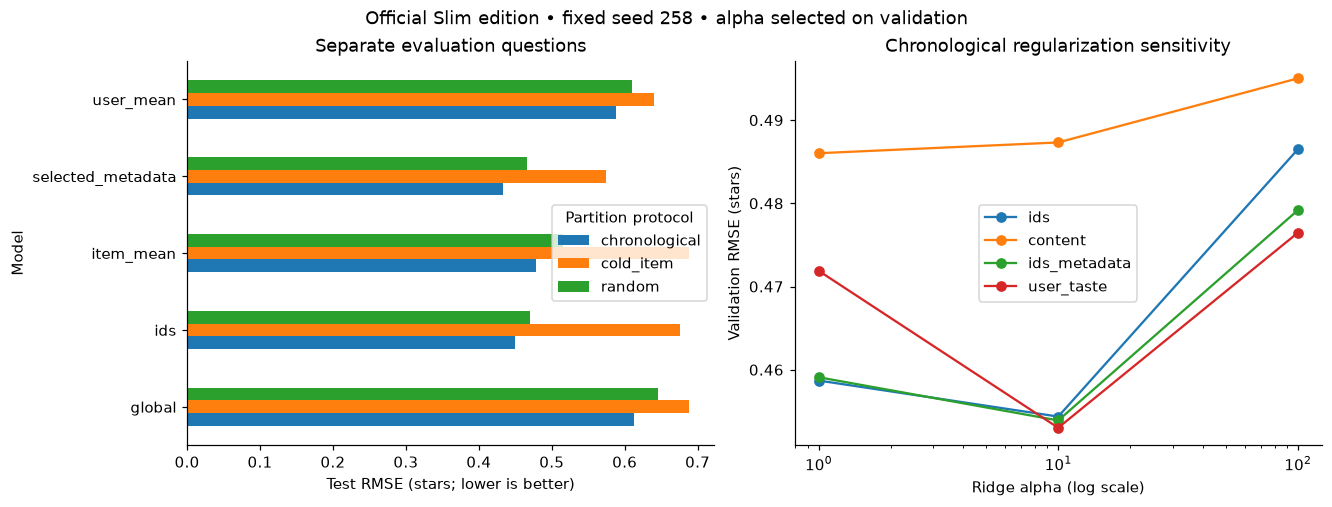

In [13]:
fig,ax = plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
scores.pivot(index='model',columns='protocol',values='rmse').plot.barh(ax=ax[0])
ax[0].set(xlabel='Test RMSE (stars; lower is better)',ylabel='Model',title='Separate evaluation questions')
ax[0].legend(title='Partition protocol')
g = results['chronological']['grid']
for name in ['ids','content','ids_metadata','user_taste']:
    s = g[g.representation.eq(name)].sort_values('alpha')
    ax[1].plot(s.alpha,s.rmse,marker='o',label=name)
ax[1].set(xscale='log',xlabel='Ridge alpha (log scale)',ylabel='Validation RMSE (stars)',
          title='Chronological regularization sensitivity')
ax[1].legend(); fig.suptitle('Official Slim edition • fixed seed 258 • alpha selected on validation')
fig.savefig(FIGURES/'feature_results.png',bbox_inches='tight'); plt.show()

## Findings

The results below summarize the fitted feature probes.

**Follow-up diagnostic disclosure:** after seeing that the primary selected probe included time, we added an IDs+time/age-only **validation** probe. This separates temporal context from wine-metadata associations. It does not access test, change the original selection, or supply independent confirmatory evidence. Avoid attributing a combined metadata+time test gain entirely to static wine attributes.

In [14]:
time_check = time_diagnostic(wines,splits['chronological'])
time_check.to_csv(REPORTS/'chronological_time_diagnostic.csv',index=False)
display(time_check)
best_val = results['chronological']['grid'].sort_values('rmse').drop_duplicates('representation')
display(best_val[['representation','alpha','train_rmse','rmse']].sort_values('rmse'))
print('IDs+time/age validation best:',round(time_check.rmse.min(),6))
print('IDs+metadata+time/age validation best:',round(best_val.set_index('representation').loc['ids_metadata_time','rmse'],6))

,representation,alpha,rmse,mae
0,ids_time_only,1.0,0.451999,0.327918
1,ids_time_only,10.0,0.445635,0.321555
2,ids_time_only,100.0,0.476342,0.346049


,representation,alpha,train_rmse,rmse
22,ids_metadata_time,10.0,0.458857,0.443972
25,user_taste,10.0,0.440489,0.453024
19,ids_metadata,10.0,0.461486,0.453905
1,ids,10.0,0.464302,0.454369
16,ids_region,10.0,0.462416,0.454375
13,ids_grapes,10.0,0.463572,0.455095
10,ids_country,10.0,0.463422,0.455296
7,ids_type,10.0,0.463934,0.455461
3,content,1.0,0.525777,0.486021


IDs+time/age validation best: 0.445635
IDs+metadata+time/age validation best: 0.443972


In [15]:
primary = results['chronological']
ci = primary['bootstrap']
base = primary['scores'].set_index('model')
word = 'supports a reduction' if ci['ci_high'] < 0 else ('supports an increase' if ci['ci_low'] > 0 else 'does not resolve a difference')
facts = [
    f"Slim contains **{len(ratings):,} ratings, {ratings.UserID.nunique():,} users and {len(wines):,} wines**; sparsity is **{audit(wines,ratings)['sparsity']:.2%}**.",
    'Prices and consumer locations are unavailable in X-Wines.',
    f"On future ratings, IDs RMSE is **{base.loc['ids','rmse']:.4f}**; the selected **{primary['selected']}** probe is **{base.loc['selected_metadata','rmse']:.4f}**. This is a combined metadata/context probe, not isolated evidence for static attributes.",
    f"Paired ΔRMSE is **{ci['delta_rmse']:+.4f}**, 95% user-bootstrap CI **[{ci['ci_low']:+.4f}, {ci['ci_high']:+.4f}]**; this {word} conditional on this run.",
    f"Validation RMSE: IDs **{best_val.set_index('representation').loc['ids','rmse']:.4f}**, IDs+static metadata **{best_val.set_index('representation').loc['ids_metadata','rmse']:.4f}**, follow-up IDs+time/age **{time_check.rmse.min():.4f}**. Check the time ablation before claiming metadata drives improvement.",
    'The disjoint-wine experiment measures prediction without item histories; it does not reconstruct product launches.'
]
display(Markdown('\n'.join('- '+f for f in facts)))
(REPORTS/'findings.md').write_text('# Findings\n\n'+'\n\n'.join('- '+f for f in facts)+'\n')

- Slim contains **150,000 ratings, 10,561 users and 1,007 wines**; sparsity is **98.59%**.
- Prices and consumer locations are unavailable in X-Wines.
- On future ratings, IDs RMSE is **0.4493**; the selected **ids_metadata_time** probe is **0.4332**. This is a combined metadata/context probe, not isolated evidence for static attributes.
- Paired ΔRMSE is **-0.0161**, 95% user-bootstrap CI **[-0.0185, -0.0136]**; this supports a reduction conditional on this run.
- Validation RMSE: IDs **0.4544**, IDs+static metadata **0.4539**, follow-up IDs+time/age **0.4456**. Check the time ablation before claiming metadata drives improvement.
- The disjoint-wine experiment measures prediction without item histories; it does not reconstruct product launches.

773

## Ranking evaluation (not executed)
Keep ranking secondary to rating prediction. Predeclare relevant = held-out rating ≥4. For a strict warm-catalogue experiment use wines with a training interaction, exclude each user's training-rated wines, and state that availability dates are unknown. Evaluate Recall@10/NDCG@10 over the entire eligible catalogue, not just a changing random negative sample; exclude users with no eligible relevant test item and report their number. Unobserved wines are unlabeled, not verified dislikes. Compare models on identical users/candidates; report catalogue coverage and diversity separately. Actual item availability at historical query dates is not established by this dataset.

## Prediction output format
See `docs/evaluation_protocol.md`. Predictions use `RatingID,prediction` for the exact test RatingIDs; matching uses IDs rather than row order. Report the dataset edition, protocol, validation selection, clipping, seed, runtime and fallback behavior. Compare published metrics only under matching evaluation protocols.

## References

- [Official X-Wines repository and version counts](https://github.com/rogerioxavier/X-Wines).
- [Official dataset distribution](https://github.com/rogerioxavier/X-Wines/blob/main/Dataset/README.MD).
- de Azambuja, Morais & Filipe (2023), [X-Wines: A Wine Dataset for Recommender Systems and Machine Learning](https://doi.org/10.3390/bdcc7010020).